# Model 1: Multinomial Naive Bayes Classifier

- **Naive Assumption**:
  The model assumes that all features \(X_i\) are independent:


### Our methord:

We will use a **Bag-of-Words (BoW)** approach to vectorize the content, and then apply Nultinomial Naive Bayes using Laplace smoothing for classification. The steps are as follows:

1. **Preprocessing**:
   - Remove any row with incomplete data
   - Remove stop words.
   - Remove Punctuation
   - Devide the dataset into train and test.
   
2. **Vectorization**:
   - Create a BoW representation for each document.
   - We are only doing this on train data so if any new word is encountered in test data set it will be ignored to avoid zero probability.

3. **Training and Testing**:
   - Fit the Naive Bayes model using the training data.
   - Applying Laplace smoothing to avoid zero probability
   - Run the model on the test data.
4. **Evaluation**:
   - We are using 4 evaluation matrices
   - Accuracy
   - Precision
   - Recall
   - F1-score


In [51]:
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [52]:
#Reading the data from the csv file
path = "./cleaned_final_data.csv"
df = pd.read_csv(path)
print(df.head())


   id                                              title  \
0   0  آریان خان نے والد کی سب سے بڑی خوبی بتا دی، ا...   
1   1  اداکارہ صحیفہ جبار نے تیزی سے اپنا وزن کیسے کم...   
2   2  کرائم پٹرول کے نوجوان اداکار کی اچانک موت، بھا...   
3   3  دیپیکا کی بیٹی کے ہمراہ پہلی جھلک سوشل میڈیا پ...   
4   4  سدھارتھ ملہوترا ماروتی سوزوکی کی مقبول گاڑی ڈز...   

                                                link  \
0  https://www.express.pk/story/2732283/arian-kha...   
1  https://www.express.pk/story/2732277/adakara-s...   
2  https://www.express.pk/story/2732263/crime-pet...   
3  https://www.express.pk/story/2732253/deepika-k...   
4  https://www.express.pk/story/2732223/sidharthm...   

                                             content     gold_label  
0  بالی ووڈ کے سپر اسٹار شاہ رُخ خان کے بڑے بیٹے ...  entertainment  
1  پاکستان شوبز کی خوبرو اداکارہ و ماڈل صحیفہ جبا...  entertainment  
2  بھارت کے ٹیلی ویژن اداکار نیتن چوہان کی گھر سے...  entertainment  
3  ممبئی: بالی وڈ کی م

In [53]:
import json
import re


def load_stopwords(file_path):
    with open(file_path, 'r', encoding='utf-8') as f:
        data = json.load(f)
    return data

urdu_stopwords = load_stopwords('./stopwords-ur.json')  

def remove_stopwords(text):
    words = text.split()  
    words = [word for word in words if word not in urdu_stopwords] 
    return ' '.join(words)

def remove_punctuation(text):
    punctuation = r'[^\w\s' + re.escape('،۔؟؛ٔ‘’"")') + r']'
    text = re.sub(punctuation, '', text)  
    return text

def clean_text(text):
    text = remove_stopwords(text) 
    text = remove_punctuation(text) 
    return text




In [54]:


df['content'] = df['content'].apply(clean_text)




In [55]:
#separting the gold labels 
X = df.drop(columns=['gold_label'])  
y = df['gold_label'] 
#Splitting the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
print(y_train)

X_train shape: (895, 4)
X_test shape: (224, 4)
y_train shape: (895,)
y_test shape: (224,)
184            sports
711     entertainment
486            sports
260             world
398          business
            ...      
466            sports
121          business
1044            world
1095            world
860            sports
Name: gold_label, Length: 895, dtype: object


In [56]:
class BagOfWords:
    def __init__(self):
        self.vocabulary = []
        self.indices = {}

    def fit(self, corpus):
        unique= set()
        for sentence in corpus:
            for word in sentence.split():
                unique.add(word)
        self.vocabulary = list(unique)
        self.indices = {word: idx for idx, word in enumerate(self.vocabulary)}

    def vectorize(self, sentence):
        vector = np.zeros(len(self.vocabulary)) 
        for word in sentence.split():
            if word in self.indices: 
                vector[self.indices[word]] += 1
        return vector

In [57]:
# # code here
bOw = BagOfWords()
bOw.fit(X_train['content'])
dataTrainVectorized = np.array([bOw.vectorize(sentence) for sentence in X_train['content']])
dataTestVectorized = np.array([bOw.vectorize(sentence) for sentence in X_test['content']])


In [58]:
classProbs = {}
featureProbs = {}  
classes = [i for i in (y_train.unique())]
def train(X, y):
    n = len(y)
    featureCount = X.shape[1]
    for label in classes:
        classProbs[label] = np.log(np.sum(y == label) / n)

    for label in classes:
        featureProbs[label] = np.zeros(featureCount)
        for i in range(featureCount):
            featureProbs[label][i] = np.sum(X[y == label, i]) + 1 
        denominator = np.sum(X[y == label]) + featureCount 
        featureProbs[label] = np.log(featureProbs[label] / denominator) 

def predict(X):
    predictions = []
    for vector in X:
        logProbs = {}
        for label in classes:
            logProb = classProbs[label]  
            logProb += np.sum(vector * featureProbs[label])  
            logProbs[label] = logProb
        pred = max(logProbs, key=logProbs.get)
        predictions.append(pred)

    return np.array(predictions)


Accuracy: 0.9642857142857143
Precision:  0.9653176199663002
Recall: 0.9642857142857143
F1 Score: 0.9641994215317115


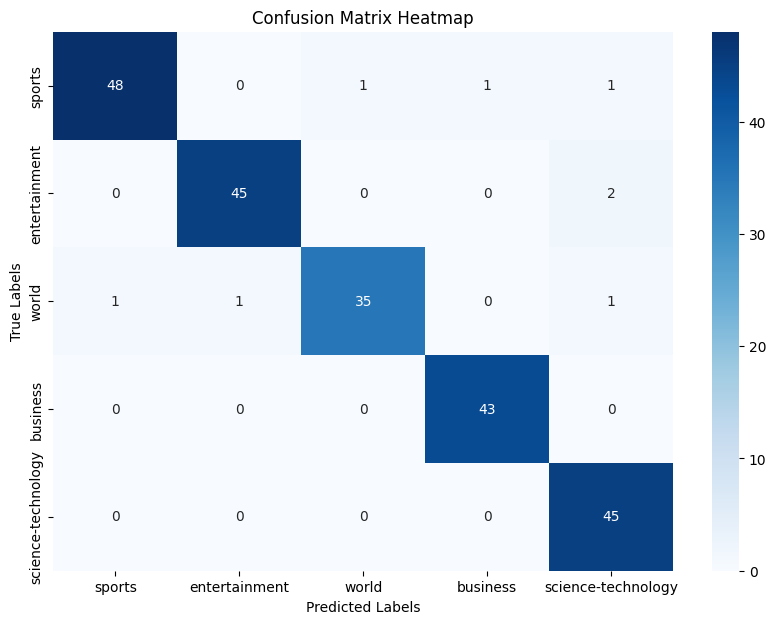

In [59]:
# code here
train(dataTrainVectorized,y_train)
predictions = predict(dataTestVectorized)
accuracy = accuracy_score(y_test,predictions)
precision = precision_score(y_test, predictions, average='weighted') 
recall = recall_score(y_test, predictions, average='weighted')
f1 = f1_score(y_test, predictions, average='weighted')
conf_matrix = confusion_matrix(y_test, predictions)
print(f"Accuracy:",accuracy)
print(f"Precision: ",precision)
print(f"Recall:",recall)
print(f"F1 Score:",f1)
confMtrix = confusion_matrix(y_test, predictions)
plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()
